# Australian MT: a spatial resistivity profile from diffusive electromagnetic measurements


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`period`，shape `(1, 23)`，dtype `<f8`：Measured sounding periods, seconds.；`log_apparent_resistivity`，shape `(1, 23)`，dtype `<f8`：Observed log10(apparent resistivity / (1 ohm metre)), dimensionless.；`log_resistivity_std`，shape `(1, 23)`，dtype `<f8`：Standard deviations of log10 apparent resistivity, dimensionless.；`impedance_phase`，shape `(1, 23)`，dtype `<f8`：Observed impedance phase in the convention defined above, radians.；`phase_std`，shape `(1, 23)`，dtype `<f8`：Standard deviations of impedance phase, radians.；`layer_top`，shape `(1, 25)`，dtype `<f8`：Reconstruction layer-top depths, metres, positive downward.。未知量为25层深度电阻率log10(ohm m)剖面。

获取模型：水平各向同性层状介质电磁扩散递推得到视电阻率及阻抗相位。

如何恢复：src.solvers.reconstruct/occam_update：解析Jacobian、粗糙度约束与阻尼搜索。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell2四组图对比两观测通道、深度剖面、迭代及target RMS敏感性。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。原始上游数值失败已明确，使用调查后纠正的上游方法参考。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


The 23 measured sounding periods probe broad, overlapping depth ranges. We reconstruct the 25-layer spatial field $m_j=\log_{10}(\rho_j/(1\,\mathrm{ohm\,m}))$, where $\rho_j$ is electrical resistivity and depth is positive downward. The final cell is a half-space. This fine grid is a representation, not a claim of 25 independently resolved geological layers.

We select the real Table 5 Australian MT case of Constable, Parker & Constable (1987), originating in Cull (1985). No synthetic observations are generated. The full selected two-channel benchmark is actively reconstructed below. The paper's separate DC-resistivity and joint-data examples are outside this MT-only acquisition and are not claimed reproduced.

**Three provenance classes remain separate:** historical paper figures; our exact-data original-code run, which fails with NaN and an independently demonstrated missing phase derivative chain factor; and our corrected-original oracle followed by the fresh local implementation. The latter two are compared numerically. No subsurface truth is available, and a method reference is never presented as truth.

## 2. Data

All arrays are stored in `data/raw_data.npz` with an explicit batch axis.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| period | (1, 23) | float64 | Measured sounding periods, seconds. |
| log_apparent_resistivity | (1, 23) | float64 | Observed log10(apparent resistivity / (1 ohm metre)), dimensionless. |
| log_resistivity_std | (1, 23) | float64 | Standard deviations of log10 apparent resistivity, dimensionless. |
| impedance_phase | (1, 23) | float64 | Observed impedance phase in the convention defined above, radians. |
| phase_std | (1, 23) | float64 | Standard deviations of impedance phase, radians. |
| layer_top | (1, 25) | float64 | Reconstruction layer-top depths, metres, positive downward. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Vacuum permeability | 4 pi times 10^-7 | H/m | Nonmagnetic constitutive parameter. |
| Surface depth | 0 | m | Plane-wave observation boundary. |
| Number of periods | 23 | 1 | Paired apparent-resistivity and phase observations. |
| Period range | 0.020 to 1995.000 | s | Actual irregular sampling is in `period`. |
| Number of layers | 25 | 1 | Piecewise constant profile; deepest layer extends to infinity. |
| Layer axes | Horizontal planes; positive depth downward | 1 | One-dimensional Earth geometry, no lateral variation. |
| Source and medium | Plane-wave source; isotropic conductive layers | 1 | Quasistatic magnetic diffusion model. |
| Bottom boundary | Homogeneous half-space | 1 | Decaying solution, C=1/q in the final layer. |
| Noise weighting | Provided marginal standard deviations; diagonal weighting assumed | 1 | Separate uncertainty scales; cross-channel covariance is unavailable. |
| Complex convention | q=sqrt(i omega mu / rho), Re(q)>0 | 1 | Fixes phase and attenuation signs. |

The arrays retain the numerical precision of the published tabulation. The layer grid is a chosen spatial discretization, not a target-derived calibration. No additional input files are required.

## 3. Physics

### Physics, discretization, and corrected derivatives

For period $T$, angular frequency is $\omega=2\pi/T$ and permeability is $\mu=4\pi\,10^{-7}$ H/m. With $q_j=\sqrt{\mathrm{i}\omega\mu/\rho_j}$, the transfer length is $C_L=1/q_L$ in the bottom half-space and


$$
C_j=\frac{q_j C_{j+1}+\tanh(q_j h_j)}{q_j[1+q_j C_{j+1}\tanh(q_j h_j)]},
$$


where $h_j$ is layer thickness in metres. Apparent resistivity is $\omega\mu|C_1|^2$ and phase is $\operatorname{atan2}(\Re C_1,-\Im C_1)$. We evaluate the exact identity $\tanh u=-\operatorname{expm1}(-2u)/(1+\exp(-2u))$ to avoid complex-tanh overflow.

Occam inversion minimizes the linearized weighted residual plus $\lambda\|Dm\|^2$, where $D$ takes adjacent log-resistivity differences. It solves for the next complete profile rather than a correction. A decade search selects the regularization tradeoff; discrepancy target 1 then selects the smoothest accepted candidate. Both measurement channels are standardized by their individual uncertainties.

The source phase derivative was expressed with respect to linear resistivity but used as a derivative with respect to $m$. Chain rule requires $d\rho/dm=\ln(10)\rho$. Restoring this factor reduces the independent finite-difference Jacobian error from 0.995657 to about $3.1\times10^{-10}$. This is an explicitly identified implementation repair, not an unchanged reproduction. Detailed diffs, original failure logs, and corrected-oracle captures are indexed in `test/validation.md`.

## 4. Method

Let $d$ concatenate the 23 log-apparent-resistivity and 23 phase observations, $F(m)$ their predicted responses, $J$ the response Jacobian, and $W$ the diagonal matrix of inverse supplied standard deviations. At current profile $m$, solve for the complete next profile $v$:

$$
(J^TW^2J+\lambda D^TD)v=J^TW^2[d-F(m)+Jm].
$$

Here $D$ takes adjacent depth differences and $\lambda$ trades roughness against standardized data fit. Initialization is $m=2$, $\lambda=10$. A decade bracket search and discrepancy-target smoothing implement the selected Occam update; the target-zero and alternate-target paths below are separate computed sensitivity experiments.

## 5. Results




# Benchmark v2: noise-compatible smooth conductivity profiles

The historical source Occam bracket/restart algorithm and its parity evidence below are unchanged. Its finite numerical trajectory is no longer the benchmark target. The v2 independent Judge measures the explicit adjacent-log-resistivity squared roughness and full46datum Maxwell forward standardized RMS, requiring RMS<=1 and roughness<=0.61705858471659. It reads no hidden field. This admits smoother equally data-compatible Earth profiles without claiming geological uniqueness. No iteration/seed/step-search parameters are required from the solver. Old v1 image metrics are privately preserved in benchmark_readiness_20261029/australia_metrics_v1.json.

Independent SLSQP from a constant100ohm-metre field solves minimum roughness subject to RMS<=0.9999, yielding roughness0.14205265603716288 and RMS0.9999000000001929; the independent control passes. A constant100ohm-metre field has RMS5.574442655363822, and the reversed improved field RMS1.9874197911335068; both fail. The first control attempted exact RMS1 and exceeded it by3.5e-13 solver feasibility roundoff; rerunning with a0.9999 control margin fixed that without changing evaluator boundaries. Full tests26passed in0.98s. Private evidence: australia_v2_controls.json, australia_v2_controls_margin.log, australia_pytest_v2.log. Existing source/arrays are unchanged; no fresh blind agent solve is claimed.



In [1]:
from pathlib import Path
import os,sys,time
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
if not (root/'data/raw_data.npz').exists(): raise RuntimeError('Execute from the task or notebooks directory')
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import response,jacobian
from src.visualization import similarity,make_figures,export_figures
data=load_data(root/'data/raw_data.npz')
t0=time.perf_counter()
model,history=reconstruct(data)
runtime=time.perf_counter()-t0
with np.load(root/'notebooks/reference_outputs/upstream_corrected.npz',allow_pickle=False) as a:
    upstream=a['reconstruction'][0].copy()
print('Fresh standard reconstruction runtime [s]:',runtime)
print('Fresh standardized observation RMS:',history['final_rms'])
print('NCC, dynamic-range NRMSE vs corrected original:',similarity(model,upstream))
print('Max absolute log-profile difference:',np.max(abs(model-upstream)))

Fresh standard reconstruction runtime [s]: 0.00910709999880055
Fresh standardized observation RMS: 0.8436476413023603
NCC, dynamic-range NRMSE vs corrected original: (0.9999999999999997, 1.391924117742106e-15)
Max absolute log-profile difference: 3.552713678800501e-15


Fresh target sensitivity: target, achieved standardized RMS, squared first-difference roughness
0.7 0.6681128736193511 0.451893410887451
1.0 0.8436476413023603 0.61705857471659
1.5 1.3944456189671717 0.06962050128040864
2.0 1.6807926085875975 2.377676072142706e-29
Fresh target-zero progression: [5.57444266 1.52482161 0.86968798 0.5097026  0.46377055 0.43552711
 0.43504613]


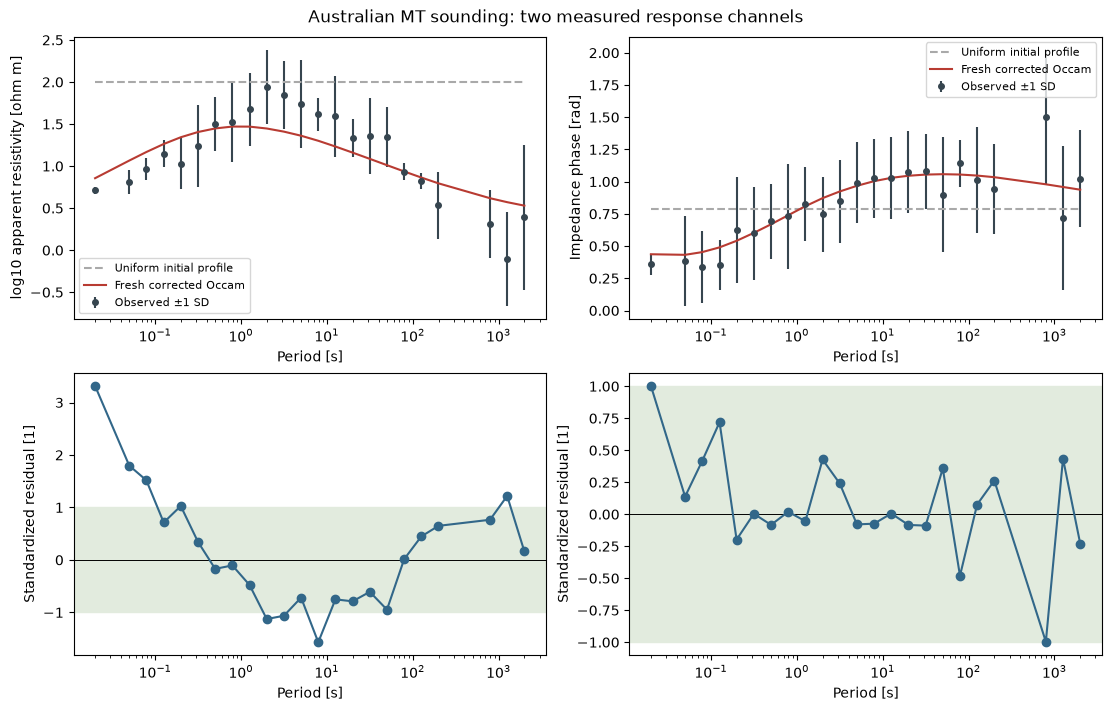

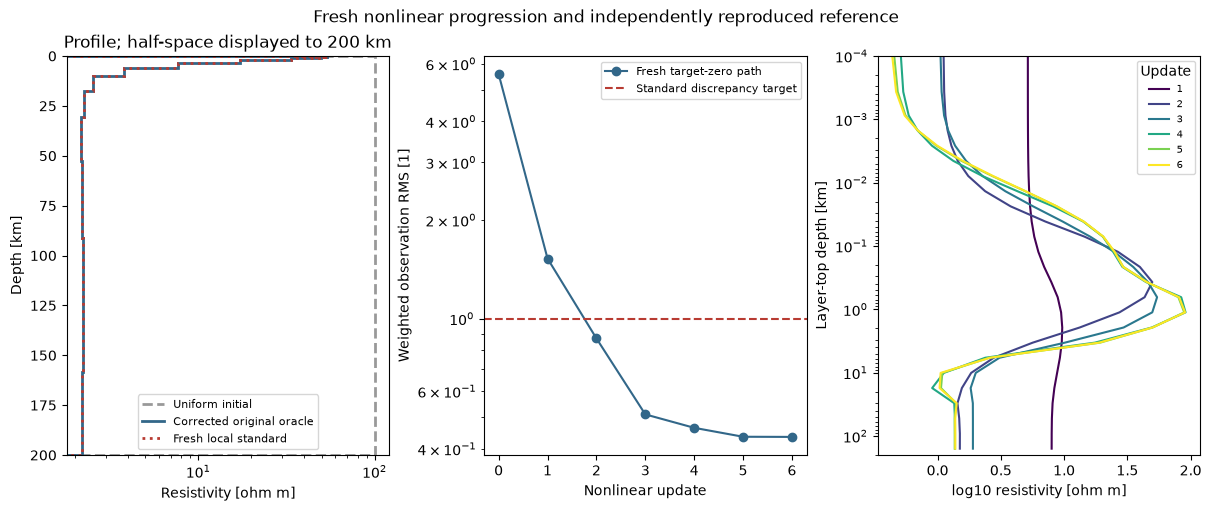

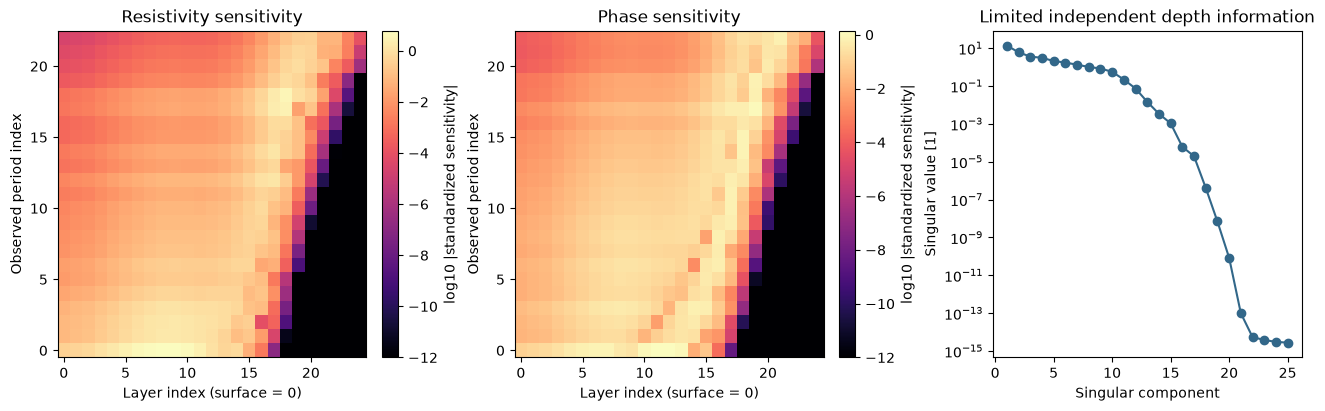

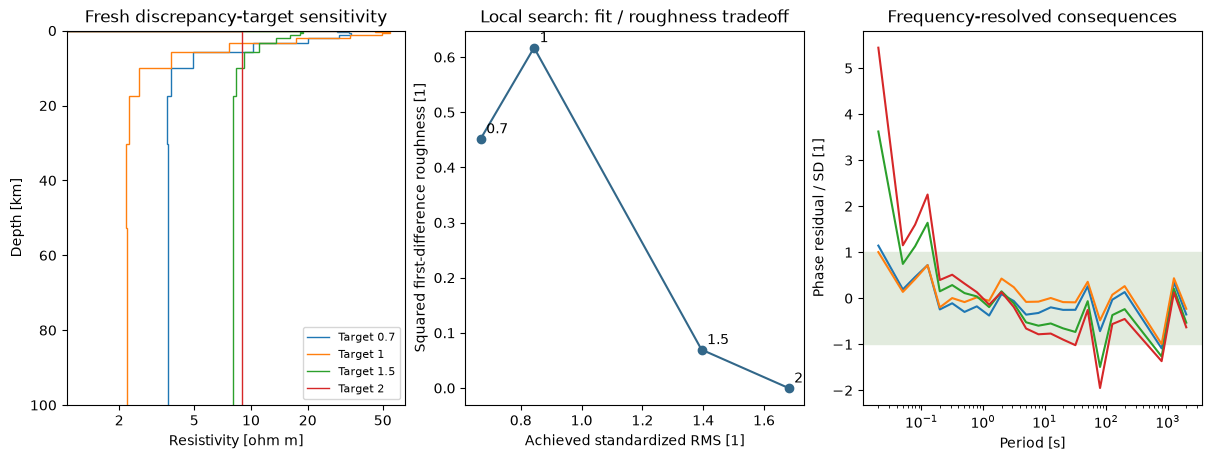

In [2]:
sensitivity={}
for target in [0.7,1.0,1.5,2.0]:
    sensitivity[target]=reconstruct(data,target_rms=target)
unconstrained_model,unconstrained=reconstruct(data,target_rms=0,max_iterations=6)
print('Fresh target sensitivity: target, achieved standardized RMS, squared first-difference roughness')
for target,(m,h) in sensitivity.items(): print(target,h['final_rms'],float(np.sum(np.diff(m)**2)))
print('Fresh target-zero progression:',unconstrained['rms'])
figures=make_figures(data,model,history,upstream,sensitivity,unconstrained)
plt.show()

### What the comparisons establish

The first group compares both measured channels, their separate uncertainties, fresh predictions, and standardized residuals. The second shows the corrected-original reference and fresh profile, the complete six-update target-zero path, and how spatial structure develops. Its half-space is displayed only to 200 km; this is a plotting limit, not a bottom boundary.

The third plots both independently computed response Jacobian blocks and their weighted singular spectrum. Sensitivities overlap strongly with depth; small singular values explain why many fine-scale profile changes are weakly observable. The fourth reconstructs four discrepancy targets from the same observations and shows the resulting roughness/fit tradeoff and period-dependent phase residuals. The decade search is local: in this case target 0.7 produces a smoother result than target 1.0, so the target family is not a monotone Pareto frontier or proof of a globally smoothest solution. These are actual new computations, with no archived result substituted for a fresh method.

A smaller data residual alone does not identify a truer profile: the target-zero sequence increasingly fits uncertain observations at the cost of roughness. Standard-reference parity supports numerical fidelity; half-space, layer-splitting, gradient and standalone-Judge tests provide separate mathematical checks. Neither implies geological uniqueness.


In [3]:
import importlib.util,json
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
prediction=root/'output/reconstruction.npz'
np.savez_compressed(prediction,reconstruction=model[None])
report,status=judge.evaluate(prediction)
print(json.dumps(report,indent=2))
assert status==0
sources={**data,'fresh_model':model,'corrected_original_model':upstream,'fresh_models_by_iteration':unconstrained['models'],'fresh_rms_by_iteration':unconstrained['rms']}
j1,j2,_=jacobian(1/data['period'],model,data['layer_top'])
sources['fresh_jacobian_log_resistivity']=j1
sources['fresh_jacobian_phase']=j2
sources['fresh_weighted_singular_values']=np.linalg.svd(np.vstack([j1/data['log_resistivity_std'][:,None],j2/data['phase_std'][:,None]]),compute_uv=False)
for target,(m,h) in sensitivity.items():
    sources[f'target_{target:g}_model']=m
    sources[f'target_{target:g}_rms']=np.array(h['final_rms'])
export=Path(os.environ.get('IMAGING_PRIVATE_EXPORT',str(next(parent for parent in root.parents if parent.name == 'tasks').parent.parent/'imaging-101-maintainer/research_batch4_20261021/astro_earth_mechanics/mt_figures')))
export_figures(figures,sources,export)
print('Private figure/source exports:',export)

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 1.3919241177421061e-15,
    "observation_rms": 0.8436476413023603
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "observation_rms": {
      "comparison": "<=",
      "boundary": 1.0
    }
  },
  "errors": []
}


Private figure/source exports: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch4_20261021\astro_earth_mechanics\mt_figures


## 6. Conclusion


The fresh local reconstruction reproduces the corrected-original smooth spatial profile while fitting the two physical observation channels within the stated uncertainty target. The profile is a regularized interpretation of real data, not measured ground truth. Original source failure, corrected-original validation, fresh reconstruction, and sensitivity analysis have separate provenance. The selected benchmark executes fully on CPU without an upstream imaging package.
